In [155]:
import os 

import xarray as xr
import numpy as np
import pandas as pd 
import fnmatch
from numpy.polynomial import Polynomial
import seaborn as sns

import cartopy.feature as cf
import healpy as hp
import cftime
from datetime import datetime, timedelta
import pyproj
import regionmask
import scipy.stats as sstats
from scipy.interpolate import griddata
import xesmf as xe 
import cmocean as cmo 
import matplotlib.ticker as mticker

#import easygems.healpix as egh
#from scipy.spatial import KDTree
import matplotlib.tri as tri

import tqdm
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import matplotlib.gridspec as gridspec
from matplotlib.animation import FuncAnimation

import numpy as np
from matplotlib.lines import Line2D



import xclim
from xclim.core.calendar import percentile_doy

# import aqua
# from aqua import Reader
# from aqua import inspect_catalog
import pyproj
pyproj.datadir.set_data_dir("/home/bsc/bsc032263/.conda/envs/aqua/share/proj")

os.chdir("/home/b/b382291/git/small_islands")

from small_island_functions import interpolate_timeseries
from small_island_functions import adjust_lon_coords
from small_island_functions import island_bounds_box
from small_island_functions import format_data
from small_island_functions import matching_resolutions_xe
from small_island_functions import summarize_mhw_events
from small_island_functions import detect_mhw_events
# from small_island_functions import summarize_period


island_bounds = island_bounds_box()

!hostname

l40073.lvt.dkrz.de


# for MHW we want to examine how the model compares against daily data, so using the NOAA data as the main comparsion. We will do this over the larger domain as well as the smaller domain. 

In [2]:
###################33 PRECIPITATION #####################################
#### import data from DestinE and from CORDEX

diff = 273.15 

root_noaa =  "/work/bb1153/b382291/caribbean/noaa_oisstv2"
root_esa =  "/work/bb1153/b382291/caribbean/esa_sstcci"
root_ifs_nemo = "/work/bb1153/b382291/caribbean/IFS-NEMO/0.1"
root_ifs_fesom = "/work/bb1153/b382291/caribbean/IFS-FESOM/0.1"
root_icon = "/work/bb1153/b382291/caribbean/ICON/0.1"

# root_mswep = "/gpfs/scratch/bsc32/bsc032263/mswep"
# root_era5_land = "/gpfs/scratch/bsc32/bsc032263/era5land"
# root_cimh = "/gpfs/scratch/bsc32/bsc032263/cimh"

islands_all = ["caribbean_islands"] 
islands_all_short = ["car"] 

In [3]:
var = "tos"

###############################3 load observational data ###############################################
noaa_sst = xr.open_dataset(f"{root_noaa}/tos_1990_01_01_to_2019_03_31.nc")
noaa_sst = noaa_sst[f"sst"]

# want latitude to run from north to south
noaa_sst = noaa_sst.sortby("lat", ascending=False)
noaa_sst = adjust_lon_coords(noaa_sst)

# print and name variable 
var_name = f"noaa_{var}"
print('variable', {var_name})
globals()[var_name] = noaa_sst.drop_duplicates("time")


############# getting MHW data ############# f"{root_noaa}", f"{var_name}_ds.nc")

var_name = f"{var_name}_mhw"
print('variable', {var_name})

# Define expected patterns explicitly
globals()[var_name] = xr.open_dataset(
        os.path.join(
            f"{root_noaa}", f"{var_name}_ds.nc")
        )


###############################3 load observational data ###############################################

esa_sst = xr.open_dataset(f"{root_esa}/tos_1990_01_to_2019_12_monthly_mean.nc")
esa_sst = esa_sst[f"{var}"]

# want latitude to run from north to south
esa_sst = esa_sst.sortby("lat", ascending=False)

# print and name variable 
var_name = f"esa_{var}"
print('variable', {var_name})
globals()[var_name] = esa_sst.drop_duplicates("time")


################################ load historical ClimateDT data ###############################################

var = "avg_tos"
var2 = "tos"

# CURRENTLY REMOVING ICON AS MISSING 2014 
roots = [root_ifs_nemo, root_ifs_fesom, root_icon]
names = ["nemo", "fesom", "icon"] # 

for index, root in enumerate(roots):

    folder_path = f"{root}"
    # Define expected patterns explicitly
    pattern_1990 = f"{var}_1990*car_crop.nc"
    pattern_2015 = f"{var}_2015*car_crop.nc"

    all_files = os.listdir(folder_path)

    files_1990 = [
        os.path.join(folder_path, filename)
        for filename in all_files
        if fnmatch.fnmatch(filename, pattern_1990)
    ]
    files_2015 = [
        os.path.join(folder_path, filename)
        for filename in all_files
        if fnmatch.fnmatch(filename, pattern_2015)
    ]

    ds1 = xr.open_dataset(files_1990[0])
    ds2 = xr.open_dataset(files_2015[0])

    ds = xr.concat([ds1, ds2], "time")

    #rename to lat lon
    ds = ds.rename({'latitude':'lat'})
    ds = ds.rename({'longitude':'lon'})

    # want to use the - notatin
    ds = adjust_lon_coords(ds[f"{var}"])
    
    var_name = f"{names[index]}_tos"
    print('variable', {var_name})
    # adjusting to degree C 
    globals()[var_name] = ds - diff 

    

    ##### now getting MHW data ############## 

    # Define expected patterns explicitly
    pattern = f"{names[index]}_{var2}_regrid_mhw_ds.nc"

    all_files = os.listdir(folder_path)

    files = [
        os.path.join(folder_path, filename)
        for filename in all_files
        if fnmatch.fnmatch(filename, pattern)
    ]

    ds = xr.open_dataset(files[0])

    var_name = f"{names[index]}_tos_mhw"
    print('variable', {var_name})
    # adjusting to degree C 
    globals()[var_name] = ds 




variable {'noaa_tos'}
variable {'noaa_tos_mhw'}
variable {'esa_tos'}
variable {'nemo_tos'}
variable {'nemo_tos_mhw'}
variable {'fesom_tos'}
variable {'fesom_tos_mhw'}
variable {'icon_tos'}
variable {'icon_tos_mhw'}


# just plot the mean over the domain first 

In [4]:
exps = ["noaa_tos", "esa_tos", "nemo_tos", "fesom_tos", "icon_tos"] # , "mean_bias"]

lat_bounds = [19,8] # 20, 7
lon_bounds = [-70, -55] # -80 to -50

start_time = "1992-01-01"
end_time = "2018-12-31"

for index, exp in enumerate(exps):

    # formatting to location and time mean
    globals()[f"{exp}"] = globals()[f"{exp}"].sel(
                lat = slice(lat_bounds[0], lat_bounds[1]), 
                lon = slice(lon_bounds[0], lon_bounds[1]),
            )

Text(0.5, 0.98, 'SST mean 1992-01-01 to 2018-12-31')

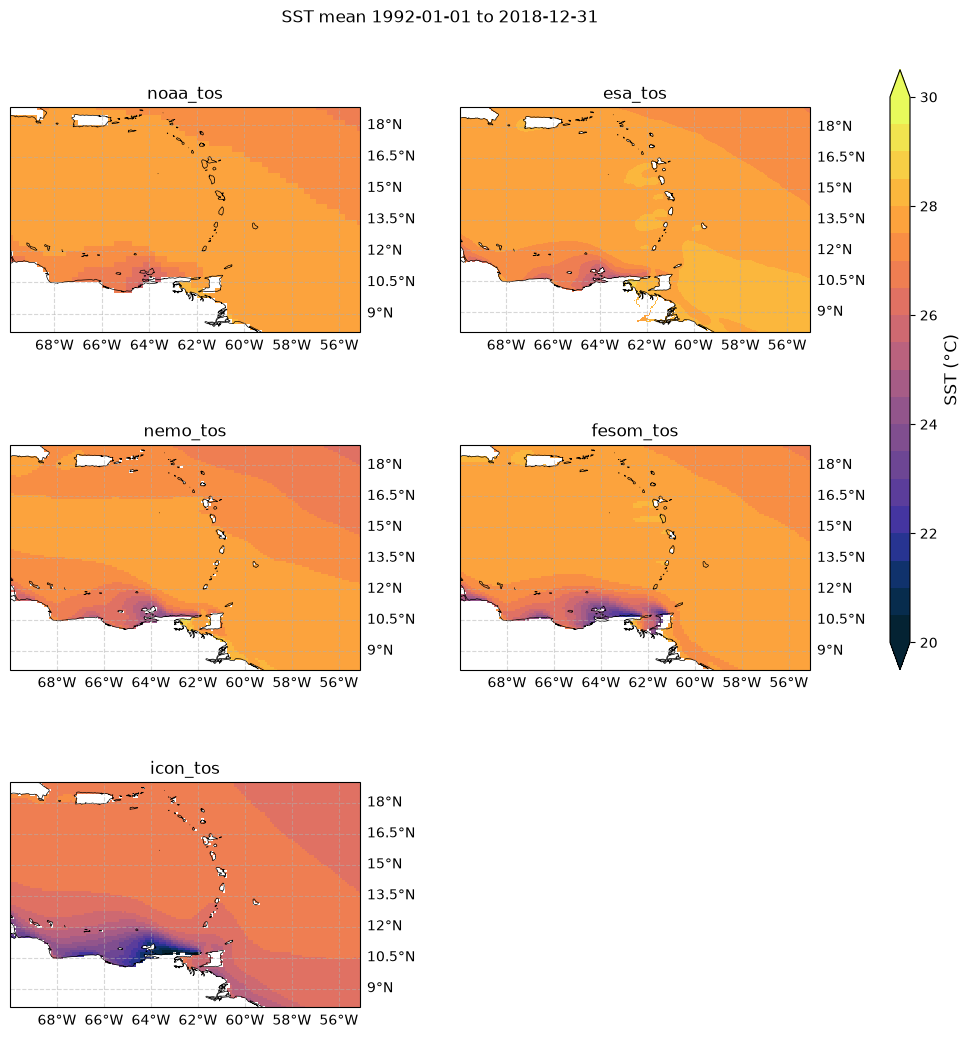

In [5]:
projection = ccrs.PlateCarree()

fsize = 12

cmap = cmo.cm.thermal
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

map_height = 0.25 # / n_islands  # 80% of row height
col_width = 0.7 / 2

fig = plt.figure(figsize=(10, 3*len(exps)/2))

for index, exp in enumerate(exps):

    # Determine subplot position
    y_map = 1 - (map_height+0.2)*(index//2 + 1) 
    x_map = 0.07 + (index % 2)*0.45


    to_plot = globals()[exp]

    # Select time period and calculate mean
    to_plot = (
        to_plot.sel(time=slice(start_time, end_time)).mean(dim="time")
    )

    ax_map = fig.add_axes([x_map, y_map, 0.35, 1.5/len(exps)], projection = projection)

    pcm = ax_map.pcolormesh(to_plot.lon, to_plot.lat, to_plot, transform=projection,
        cmap=cmap, shading="auto",vmin=20, vmax=30
    )

    # --- Map extent ---
    ax_map.set_extent(
        [
            float(to_plot.lon.min()),
            float(to_plot.lon.max()),
            float(to_plot.lat.min()),
            float(to_plot.lat.max())
        ],
        crs=projection
    )
    ax_map.set_aspect('auto')  # <- this is the key
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax_map.set_title(exp, fontsize=fsize)

    gl = ax_map.gridlines(
        draw_labels=False,
        linestyle="dashed",
        alpha=0.5
    )
    gl.bottom_labels = True
    gl.right_labels = True

    ax_map.set_title(f"{exp}")

ax_cbar = fig.add_axes([0.95, 0.1, 0.02, 0.8])
cbar = fig.colorbar(pcm, cax=ax_cbar, orientation="vertical", 
                    shrink=0.8, pad=0.05, extend = "both"
                )
cbar.set_label("SST (°C)", fontsize=fsize)

fig.suptitle(f"SST mean {start_time} to {end_time}",fontsize=fsize)


# looking at MHW threshold based on 90th percentile 

In [6]:
exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

percentile = 90

regrid = True

for exp in exps:

    da_mean = globals()[f'{exp}']

    # # # Collapse to domain-averaged SST (1D time series)
    # # # adjust dim names ('lat','lon') to match your dataset
    # # da_mean = da #.mean(dim=["lat", "lon"], skipna=True)

    if regrid and exp in ["nemo_tos", "fesom_tos", "icon_tos"]:

        # regrid grid in, grid out 
        regridder = xe.Regridder(da_mean ,globals()[f"noaa_tos"], "bilinear")
        da_mean = regridder(da_mean, keep_attrs=True)

        # da_mean = matching_resolutions_xe(
        #     da_mean, globals()[f"noaa_tos"], False,  method = "bilinear"
        # )

    globals()[f'{exp}'] = da_mean

    # the length of time you want to make your MHW threshold 
    da_mean_clim = da_mean.sel(time = slice(start_time, end_time))

    # Compute day-of-year 90th percentile threshold with 11-day window
    threshold_doy = percentile_doy(
        da_mean_clim,
        window=11,
        per=percentile
    )

    if "percentiles" in threshold_doy.coords:
        threshold_doy = threshold_doy.squeeze("percentiles", drop=True)

    # ignoring the first 2 years 
    to_plot = da_mean.sel(time = slice(start_time, None))
    threshold_full = threshold_doy.sel(dayofyear=to_plot.time.dt.dayofyear)
    globals()[f"{exp}_threshold_doy"] = threshold_full



/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/xclim/core/utils.py:554: RuntimeWarning: All-NaN slice encountered
  result = np.where(np.isnan(interpolation), np.nanmax(arr, axis=0), interpolation)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/xclim/core/utils.py:554: RuntimeWarning: All-NaN slice encountered
  result = np.where(np.isnan(interpolation), np.nanmax(arr, axis=0), interpolation)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/xclim/core/utils.py:554: RuntimeWar

Text(0.5, 0.98, '90th percentile threshold for JJA')

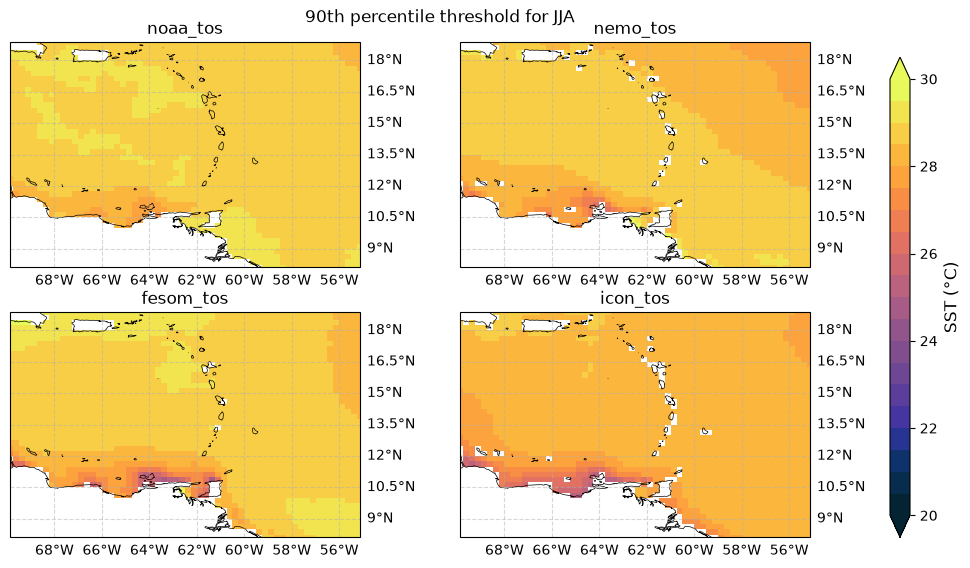

In [7]:
projection = ccrs.PlateCarree()

season = "JJA"
cmap = cmo.cm.thermal
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

fig = plt.figure(figsize=(10, 3*len(exps)/2))

for index, exp in enumerate(exps):

    # Determine subplot position
    y_map = 1 - (map_height+0.2)*(index//2 + 1) 
    x_map = 0.07 + (index % 2)*0.45


    to_plot = globals()[f"{exp}_threshold_doy"].groupby("time.season").mean()
    to_plot = to_plot.sel(season = season)

    ax_map = fig.add_axes([x_map, y_map, 0.35, 1.5/len(exps)], projection = projection)

    pcm = ax_map.pcolormesh(to_plot.lon, to_plot.lat, to_plot, transform=projection,
        cmap=cmap, shading="auto",vmin=20, vmax=30
    )

    # --- Map extent ---
    ax_map.set_extent(
        [
            float(to_plot.lon.min()),
            float(to_plot.lon.max()),
            float(to_plot.lat.min()),
            float(to_plot.lat.max())
        ],
        crs=projection
    )
    ax_map.set_aspect('auto')  # <- this is the key
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax_map.set_title(exp, fontsize=fsize)

    gl = ax_map.gridlines(
        draw_labels=False,
        linestyle="dashed",
        alpha=0.5
    )
    gl.bottom_labels = True
    gl.right_labels = True

    ax_map.set_title(f"{exp}")

# cbar_ax = fig.add_axes([0, -0.05, 0.9, 0.02])
# cbar = fig.colorbar(pcm, cax=cbar_ax, orientation = "horizontal", shrink = 0.5, extend = "both")
# cbar.set_label("SST (°C)", fontsize=fsize)


ax_cbar = fig.add_axes([0.95, 0.1, 0.02, 0.8])
cbar = fig.colorbar(pcm, cax=ax_cbar, orientation="vertical", 
                    shrink=0.8, pad=0.05, extend = "both"
                )
cbar.set_label("SST (°C)", fontsize=fsize)

fig.suptitle(f"90th percentile threshold for {season}",fontsize=fsize)



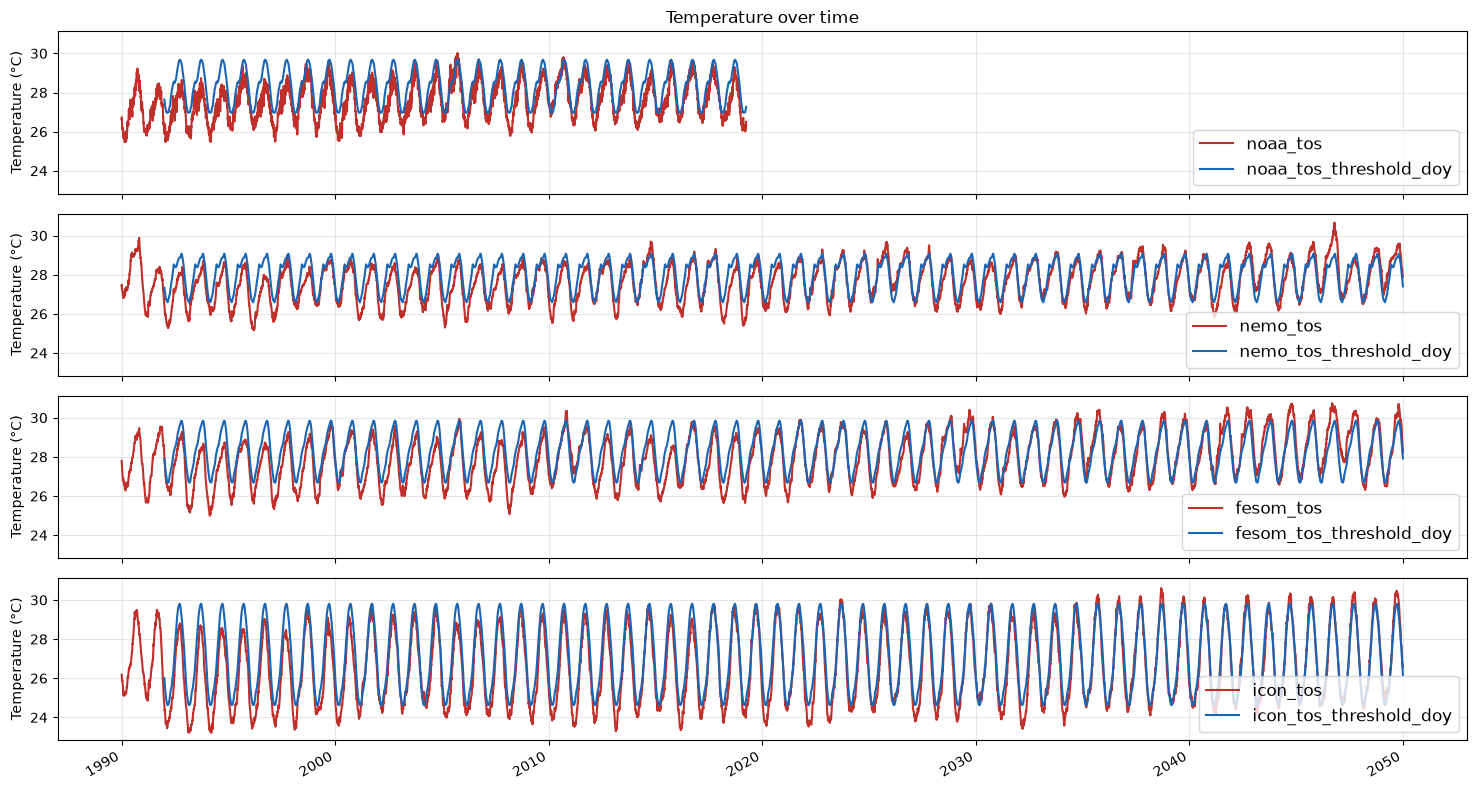

In [8]:
fs = 12

# exps = ["noaa_tos", "noaa_tos_threshold_doy", "nemo_tos", "nemo_tos_threshold_doy"]
exps = [
    ["noaa_tos", "noaa_tos_threshold_doy"],
    ["nemo_tos", "nemo_tos_threshold_doy"],
    ["fesom_tos", "fesom_tos_threshold_doy"],
    ["icon_tos", "icon_tos_threshold_doy"]

]
colors = [ "#c02f2a", "#1a65b4", "#000000",  "#8d46c7"] # sns.dark_palette("xkcd:golden", 8)

fig, axes = plt.subplots(len(exps), 1, figsize=(15, 8), sharex=True, sharey=True)

for big_index, exp_group in enumerate(exps):

    ax = axes[big_index]

    for index, exp in enumerate(exp_group):

        try:
            to_plot = globals()[f"{exp}"].mean(dim = ["lat", "lon"])
        except ValueError:
            to_plot = globals()[f"{exp}"]

        ax.plot(to_plot.time, to_plot,  
                color=colors[index],
                label = exp,
                linewidth=1.5)

    ax.grid(alpha=0.3)
    ax.set_ylabel("Temperature (°C)")
    ax.legend(fontsize = fs, loc = "lower right")

    if big_index == 0:
        ax.set_xlabel("Time")
        ax.set_title("Temperature over time")

fig.autofmt_xdate()  # rotates date labels for readability

plt.tight_layout()
plt.show()

In [9]:

exps = ["noaa_tos","nemo_tos", "fesom_tos", "icon_tos"]

# detect MHW over the whole period 
for exp in exps:
    # now have this data saved 
    # ds = globals()[f"{exp}"]
    # globals()[f"{exp}_mhw_ds"] = detect_mhw_events(
    #                                 ds.sel(time = slice(start_time, None)), 
    #                                 globals()[f"{exp}_threshold_doy"], 
    #                                 min_duration=5
    #                             )

    globals()[f"{exp}_mhw_summary"]  = summarize_mhw_events(
                                    globals()[f"{exp}_mhw"]
                                )

In [12]:
fesom_tos_mhw_summary

,event_id,start_time,end_time,mid_time,duration_days,mean_sst,max_sst,max_area_cells,mean_area_cells,footprint_cells,lat_min,lat_max,lon_min,lon_max,centroid_lat,centroid_lon
0,1,1992-01-01,1992-03-19,1992-02-09 00:00:00,79.0,27.576962,28.955660,1376.0,760.063291,1682,8.125,18.125,-69.875,-55.125,13.284483,-61.638527
1,2,1992-01-01,1992-01-06,1992-01-03 12:00:00,6.0,27.672748,27.842622,18.0,10.666667,18,16.625,18.125,-59.875,-58.875,17.458334,-59.375000
2,3,1992-02-07,1992-02-16,1992-02-11 12:00:00,10.0,26.058149,26.929045,6.0,2.300000,6,10.375,10.875,-62.125,-61.625,10.583333,-61.875000
3,4,1992-02-09,1992-02-13,1992-02-11 00:00:00,5.0,25.700929,26.328826,2.0,1.400000,2,11.625,11.625,-69.375,-69.125,11.625000,-69.250000
4,5,1992-02-09,1992-02-16,1992-02-12 12:00:00,8.0,25.776594,26.201617,13.0,6.750000,16,10.625,11.125,-67.875,-66.375,10.937500,-67.171875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3369,3070,2049-08-19,2049-08-23,2049-08-21 00:00:00,5.0,25.677380,25.833240,1.0,1.000000,1,10.875,10.875,-63.375,-63.375,10.875000,-63.375000
3370,3071,2049-08-21,2049-09-17,2049-09-03 12:00:00,28.0,26.271200,27.022824,1.0,1.000000,1,10.625,10.625,-63.875,-63.875,10.625000,-63.875000
3371,3072,2049-08-25,2049-09-04,2049-08-30 00:00:00,11.0,26.470773,26.802884,5.0,2.000000,5,10.625,11.125,-64.375,-64.125,10.925000,-64.275002
3372,3073,2049-10-08,2049-10-12,2049-10-10 00:00:00,5.0,28.724517,29.118082,6.0,4.400000,7,8.125,8.625,-59.625,-58.625,8.339286,-59.160713


In [14]:
globals()[f"noaa_tos_mhw"]

ds = globals()[f"noaa_tos_mhw"] # .event_duration

da = ds.event_duration

# stack lat/lon/time into a flat index, then find the argmax
idx = da.argmax(dim=da.dims, skipna=True)  # dict of {dim: index}

point = da.isel(idx)

lat_val = point["lat"].item()
lon_val = point["lon"].item()
time_val = point["time"].values

print(f"Max event_duration = {point.values.item()} \
      at lat={lat_val}, lon={lon_val}, time={time_val}")

# isolate that point

ds = ds.sel(lat = lat_val, lon = lon_val)

Max event_duration = 301.0       at lat=18.375, lon=-69.625, time=2009-12-17T00:00:00.000000000


mean over domain for noaa_tos: 301.0 days
mean over domain for nemo_tos: 448.0 days
mean over domain for fesom_tos: 500.0 days
mean over domain for icon_tos: 409.0 days


Text(0.5, 0.98, 'mean duration of MHW 1992-01-01 to 2018-12-31')

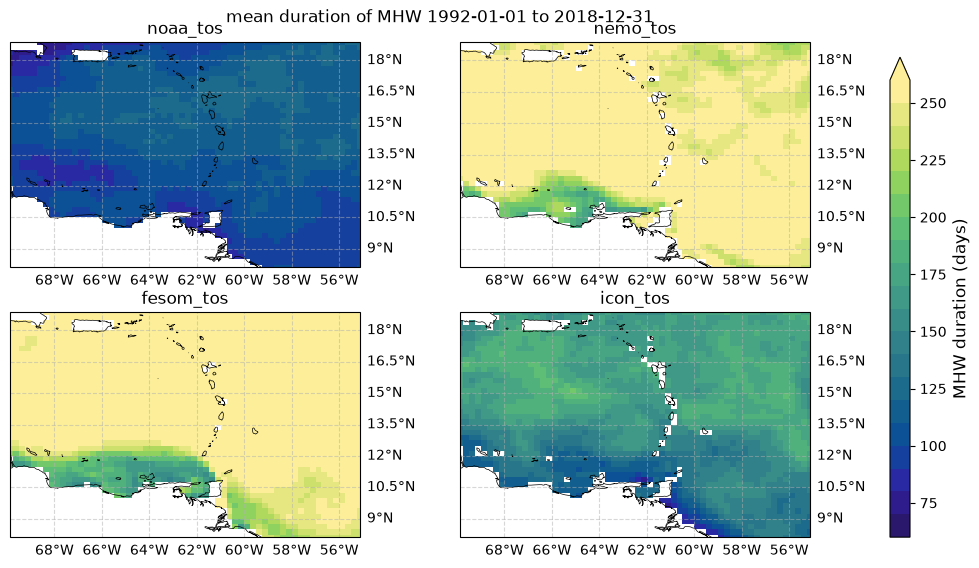

In [18]:
projection = ccrs.PlateCarree()

cmap = cmo.cm.haline # thermal
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

fig = plt.figure(figsize=(10, 3*len(exps)/2))

for index, exp in enumerate(exps):

    # Determine subplot position
    y_map = 1 - (map_height+0.2)*(index//2 + 1) 
    x_map = 0.07 + (index % 2)*0.45


    to_plot_all = globals()[f"{exp}_mhw"].sel(time = slice(start_time, end_time))

    to_plot = to_plot_all.event_duration.mean("time", skipna = True)
    #to_plot = to_plot.event_id.max("time", skipna = True)

    maximum = to_plot_all.event_duration.max("time", skipna = True)
    print(f'mean over domain for {exp}: {maximum.max().values} days')
    ax_map = fig.add_axes([x_map, y_map, 0.35, 1.5/len(exps)], projection = projection)

    pcm = ax_map.pcolormesh(to_plot.lon, to_plot.lat, to_plot, transform=projection,
        cmap=cmap, shading="auto",vmin=60, vmax=260
    )

    # --- Map extent ---
    ax_map.set_extent(
        [
            float(to_plot.lon.min()),
            float(to_plot.lon.max()),
            float(to_plot.lat.min()),
            float(to_plot.lat.max())
        ],
        crs=projection
    )
    ax_map.set_aspect('auto')  # <- this is the key
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax_map.set_title(exp, fontsize=fsize)

    gl = ax_map.gridlines(
        draw_labels=False,
        linestyle="dashed",
        alpha=0.5
    )
    gl.bottom_labels = True
    gl.right_labels = True

    ax_map.set_title(f"{exp}")
    #print(to_plot.max().values)
# cbar_ax = fig.add_axes([0, -0.05, 0.9, 0.02])
# cbar = fig.colorbar(pcm, cax=cbar_ax, orientation = "horizontal", shrink = 0.5, extend = "both")
# cbar.set_label("SST (°C)", fontsize=fsize)


ax_cbar = fig.add_axes([0.95, 0.1, 0.02, 0.8])
cbar = fig.colorbar(pcm, cax=ax_cbar, orientation="vertical", 
                    shrink=0.8, pad=0.05, extend = "max"
                )
cbar.set_label("MHW duration (days)", fontsize=fsize)

fig.suptitle(f"mean duration of MHW {start_time} to {end_time}",fontsize=fsize)



mean excess temp over 90th percentile noaa_tos: 0.2666874004655231
mean excess temp over 90th percentile nemo_tos: 0.20316373430262533
mean excess temp over 90th percentile fesom_tos: 0.26894132432138823
mean excess temp over 90th percentile icon_tos: 0.22931055863257768


Text(0.5, 0.98, 'mean intensity of MHW 1992-01-01 to 2018-12-31')

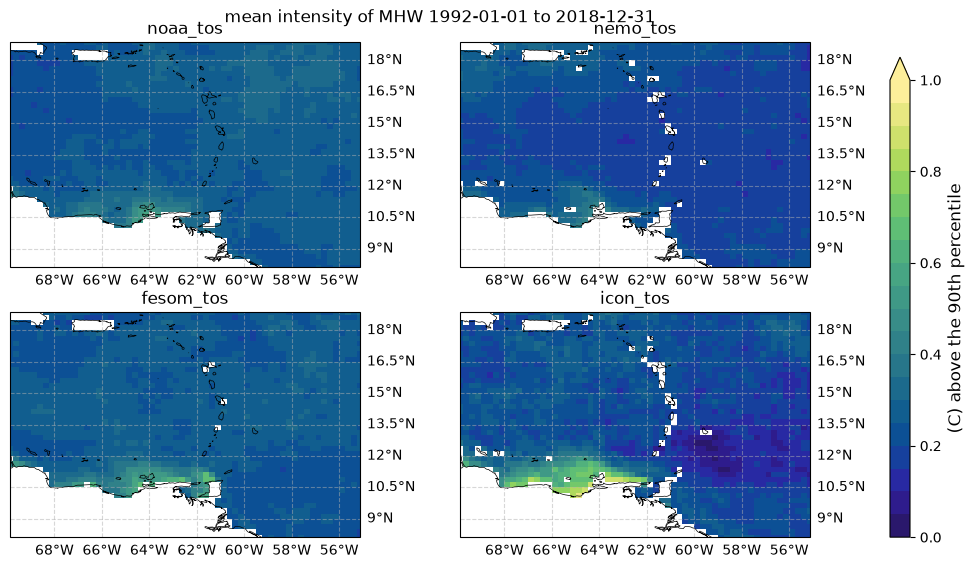

In [20]:
projection = ccrs.PlateCarree()

cmap = cmo.cm.haline # thermal
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

fig = plt.figure(figsize=(10, 3*len(exps)/2))

for index, exp in enumerate(exps):

    # Determine subplot position
    y_map = 1 - (map_height+0.2)*(index//2 + 1) 
    x_map = 0.07 + (index % 2)*0.45

    threshold = globals()[f"{exp}_threshold_doy"].mean("time", skipna=True) #.groupby("time.season").mean()

    mhw_sst = globals()[f"{exp}_mhw"].sel(time = slice(start_time, end_time))
    mhw_sst = mhw_sst.sst_mhw.mean("time", skipna=True)

    to_plot = mhw_sst - threshold

    print(f'mean excess temp over 90th percentile {exp}: {to_plot.mean().values}')
    ax_map = fig.add_axes([x_map, y_map, 0.35, 1.5/len(exps)], projection = projection)

    pcm = ax_map.pcolormesh(to_plot.lon, to_plot.lat, to_plot, transform=projection,
        cmap=cmap, shading="auto",vmin=0, vmax=1
    )

    # --- Map extent ---
    ax_map.set_extent(
        [
            float(to_plot.lon.min()),
            float(to_plot.lon.max()),
            float(to_plot.lat.min()),
            float(to_plot.lat.max())
        ],
        crs=projection
    )
    ax_map.set_aspect('auto')  # <- this is the key
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax_map.set_title(exp, fontsize=fsize)

    gl = ax_map.gridlines(
        draw_labels=False,
        linestyle="dashed",
        alpha=0.5
    )
    gl.bottom_labels = True
    gl.right_labels = True

    ax_map.set_title(f"{exp}")
    #print(to_plot.max().values)
# cbar_ax = fig.add_axes([0, -0.05, 0.9, 0.02])
# cbar = fig.colorbar(pcm, cax=cbar_ax, orientation = "horizontal", shrink = 0.5, extend = "both")
# cbar.set_label("SST (°C)", fontsize=fsize)


ax_cbar = fig.add_axes([0.95, 0.1, 0.02, 0.8])
cbar = fig.colorbar(pcm, cax=ax_cbar, orientation="vertical", 
                    shrink=0.8, pad=0.05, extend = "max"
                )
cbar.set_label("(C) above the 90th percentile", fontsize=fsize)

fig.suptitle(f"mean intensity of MHW {start_time} to {end_time}",fontsize=fsize)



In [22]:
event_summary

,event_id,start_time,end_time,mid_time,duration_days,mean_sst,max_sst,max_area_cells,mean_area_cells,footprint_cells,lat_min,lat_max,lon_min,lon_max,centroid_lat,centroid_lon
0,1,1992-05-25,1992-05-30,1992-05-27 12:00:00,6.0,28.227692,28.760000,18.0,8.666667,18,11.625,12.375,-69.875,-68.625,11.944445,-69.347221
1,2,1992-12-01,1992-12-05,1992-12-03 00:00:00,5.0,28.702238,29.070000,55.0,28.600000,77,11.125,13.375,-69.875,-66.375,12.134740,-68.176949
2,3,1993-04-09,1993-04-16,1993-04-12 12:00:00,8.0,27.002741,27.799999,110.0,40.125000,152,10.125,12.875,-69.875,-64.125,11.495066,-66.800987
3,4,1993-04-15,1993-04-19,1993-04-17 00:00:00,5.0,26.134705,26.699999,6.0,3.400000,10,10.375,11.125,-64.875,-64.125,10.700000,-64.474998
4,5,1993-05-18,1993-06-03,1993-05-26 00:00:00,17.0,28.308193,29.629999,178.0,56.352941,303,8.125,12.875,-69.875,-58.375,11.012789,-64.508667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
702,608,2019-02-05,2019-02-10,2019-02-07 12:00:00,6.0,26.218750,26.539999,31.0,18.666667,39,17.125,18.875,-56.875,-55.125,17.945513,-55.791668
703,609,2019-02-05,2019-02-09,2019-02-07 00:00:00,5.0,26.778700,26.930000,33.0,15.400000,36,14.125,15.875,-56.875,-55.125,14.868055,-55.805557
704,610,2019-02-06,2019-02-11,2019-02-08 12:00:00,6.0,26.991837,27.340000,28.0,16.333333,39,11.625,13.625,-66.375,-63.375,12.567307,-65.003204
705,611,2019-02-06,2019-02-12,2019-02-09 00:00:00,7.0,26.457207,26.699999,8.0,6.142857,11,10.875,11.125,-63.375,-62.125,10.988636,-62.693180


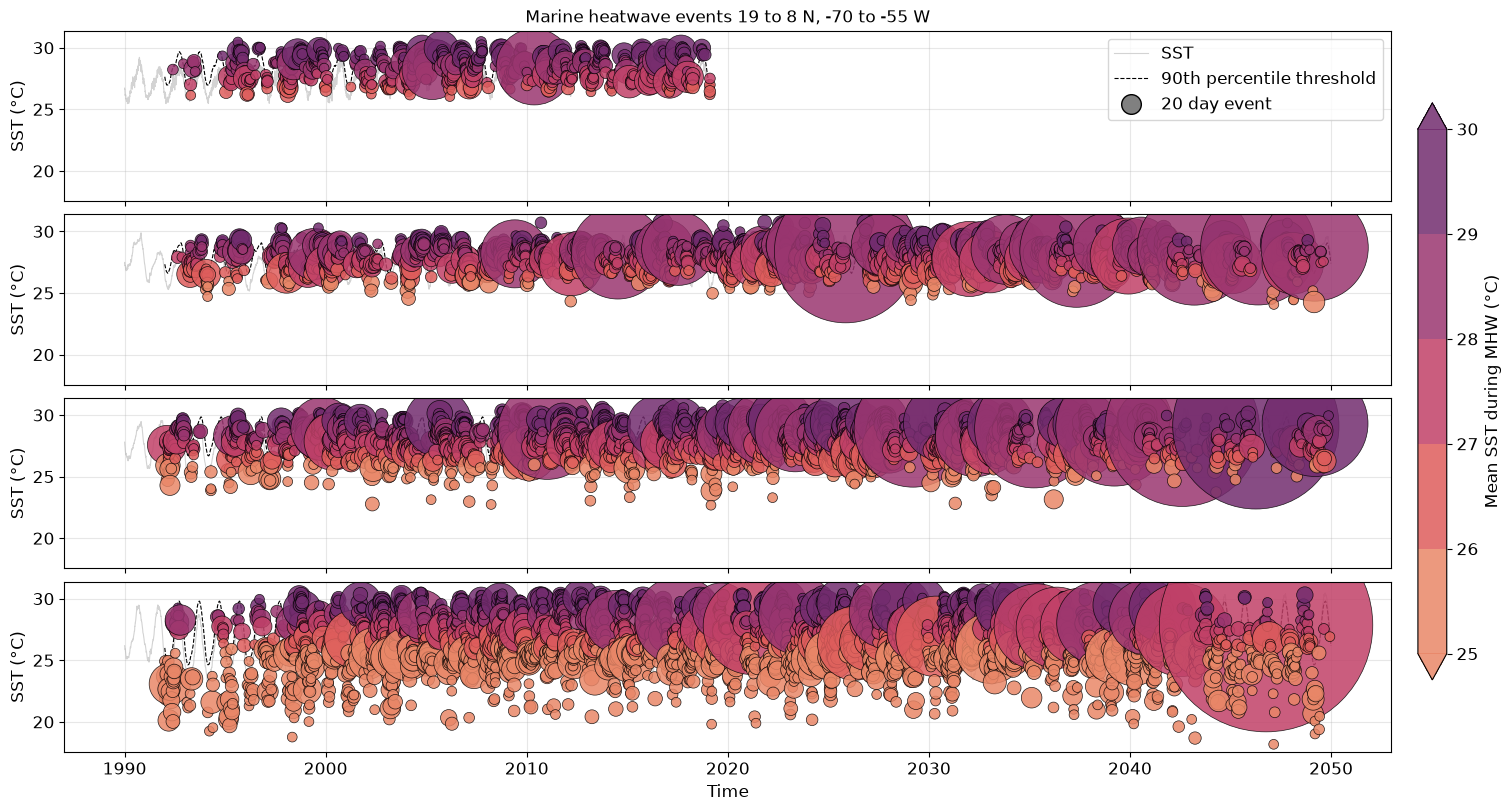

In [23]:
# --- Plot ---
fs = 12 

exps = [
    ["noaa_tos", "noaa_tos_threshold_doy"],
    ["nemo_tos", "nemo_tos_threshold_doy"],
    ["fesom_tos", "fesom_tos_threshold_doy"],
    ["icon_tos", "icon_tos_threshold_doy"]
]

fig, axes = plt.subplots(len(exps), 1, figsize=(15, 8), 
                         sharex=True, 
                         sharey=True, 
                         constrained_layout = True
                        )

for big_index, exp_group in enumerate(exps):

    ax = axes[big_index]

    to_plot = globals()[f"{exp_group[0]}"].mean(dim = ["lat", "lon"])
    to_plot_threshold = globals()[f"{exp_group[1]}"].mean(dim = ["lat", "lon"])

    # Optional: plot the full SST time series in the background for context
    ax.plot(to_plot.time, to_plot, color="lightgray", linewidth=0.8, zorder=1, label="SST")
    ax.plot(to_plot_threshold.time, to_plot_threshold, color="black",
            linewidth=0.8, linestyle="--", zorder=1, label=f"{percentile}th percentile threshold")

    palette = sns.color_palette("flare", 5)
    cmap = ListedColormap(palette)

    # --- Summarize events ---
    event_summary = globals()[f"{exp_group[0]}_mhw_summary"] 

    # Bubble scatter: size ~ duration, color ~ mean temperature
    scale_factor = 10  # adjust so bubble sizes look reasonable 
    sc = ax.scatter(
        event_summary["mid_time"],
        event_summary["mean_sst"],
        s=event_summary["duration_days"] * scale_factor,
        c=event_summary["mean_sst"],
        vmin=25, vmax=30,
        cmap=cmap,
        edgecolor="black",
        linewidth=0.5,
        alpha=0.85,
        zorder=2
    )

    example_duration = 20
    example_size = example_duration * scale_factor  # matches the 's=' scaling used in scatter

    size_legend_marker = Line2D(
        [], [],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markeredgecolor='black',
        markersize=np.sqrt(example_size),  # scatter uses area (s=), legend markersize is linear
        linestyle='None',
        label=f'{example_duration} day event'
    )

    ax.grid(alpha=0.3)

    if big_index == 0:
        ax.set_title(
            f"Marine heatwave events {lat_bounds[0]} to {lat_bounds[1]} N, {lon_bounds[0]} to {lon_bounds[1]} W",
            fontsize = fs)
        #ax.legend(loc="upper left", fontsize = fs)
    elif big_index == len(exps)-1:
        ax.set_xlabel("Time", fontsize = fs)

    ax.set_ylabel("SST (°C)", fontsize = fs)
    ax.tick_params(labelsize = fs)

cbar = fig.colorbar(sc, ax=axes, orientation = "vertical", 
                shrink = 0.8, 
                location = "right",
                pad = 0.02,
                extend = "both"
            )

cbar.set_label("Mean SST during MHW (°C)", fontsize = fs)
cbar.ax.tick_params(labelsize=fs)

# Combine with your existing line legend (SST / threshold), or make a separate one
existing_handles, existing_labels = axes[0].get_legend_handles_labels()
axes[0].legend(
    handles=existing_handles + [size_legend_marker],
    loc='upper right', fontsize = fs
)

#plt.tight_layout()
plt.show()

min 0.010259961008738827 max 0.10877567954395317
min 14.0 max 14.0


Text(0.5, 0.98, 'Marine heatwaves in nemo\n                 date 1997-03-16\n                 event number 2761')

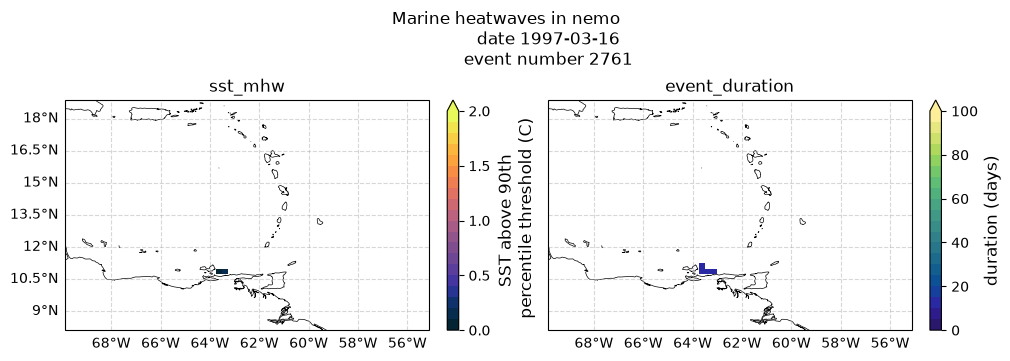

In [154]:
exp_name = "nemo"
projection = ccrs.PlateCarree()

cmap = cmo.cm.haline # thermal
cmap = cmap(np.linspace(0, 1, 20))
cmap = ListedColormap(cmap)

cmap1 = cmo.cm.thermal
cmap1 = cmap1(np.linspace(0, 1, 20))
cmap1 = ListedColormap(cmap1)
cmaps = [cmap1, cmap]

climits = [[0, 2], [0, 100]]
exps = ["sst_mhw", "event_duration"] # , "event_max_area", "event_id"]
cmap_labels = ["SST above 90th\n percentile threshold (C)", "duration (days)"]
fig, axes = plt.subplots(
    int(len(exps)/2), 2,
    figsize=(10, 3.5*len(exps)/2),
    subplot_kw={"projection": projection},
    constrained_layout=True,
    squeeze=False,
)

axes = axes.ravel()

for index, (exp, ax_map) in enumerate(zip(exps, axes)):

    mhw_sst = globals()[f"{exp_name}_tos_mhw"].sel(time=slice(start_time, end_time))
    mhw_sst = mhw_sst[f"{exp}"]  # .mean("time", skipna=True)
    to_plot = mhw_sst.isel(time=1900 + index)

    if exp == "sst_mhw":
        to_plot = to_plot - globals()[f"{exp_name}_tos_threshold_doy"].isel(time=1900 + index)

    cmin = to_plot.min().values
    cmax = to_plot.max().values
    print('min', cmin, "max", cmax)

    pcm = ax_map.pcolormesh(
        to_plot.lon, to_plot.lat, to_plot,
        transform=projection,
        cmap=cmaps[index], shading="auto", vmin=climits[index][0], vmax=climits[index][1],
    )

    # --- Map extent ---
    ax_map.set_extent(
        [
            float(to_plot.lon.min()),
            float(to_plot.lon.max()),
            float(to_plot.lat.min()),
            float(to_plot.lat.max()),
        ],
        crs=projection,
    )
    ax_map.set_aspect('auto')
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax_map.set_title(exp, fontsize=fsize)

    gl = ax_map.gridlines(
        draw_labels=False,
        linestyle="dashed",
        alpha=0.5,
    )

    if index in [0, 2]:
        gl.left_labels = True
    gl.bottom_labels = True

    cbar = fig.colorbar(pcm, ax=ax_map, orientation="vertical",
                        pad=0.05, extend = "max")
    cbar.set_label(f"{cmap_labels[index]}", fontsize=fsize)

event_number = globals()[f"{exp_name}_tos_mhw"]["event_id"].max().values
date_str = pd.Timestamp(to_plot.time.values).strftime("%Y-%m-%d")

fig.suptitle(f"Marine heatwaves in {exp_name}\n \
                date {date_str}\n \
                event number {event_number}", 
                fontsize=fsize
            )


# build animation of the heatwave evolution 

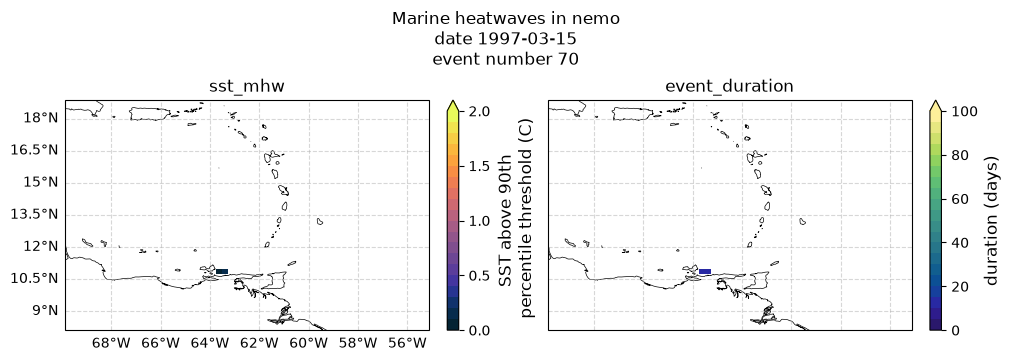

In [ ]:

exp_name = "nemo"
projection = ccrs.PlateCarree()

cmap = cmo.cm.haline
cmap = ListedColormap(cmap(np.linspace(0, 1, 20)))

cmap1 = cmo.cm.thermal
cmap1 = ListedColormap(cmap1(np.linspace(0, 1, 20)))
cmaps = [cmap1, cmap]

climits = [[0, 2], [0, 100]]
exps = ["sst_mhw", "event_duration"]  # , "event_max_area", "event_id"]
cmap_labels = ["SST above 90th\n percentile threshold (C)", "duration (days)"]

# --- Data, sliced once (load into memory so each frame is fast) ---
mhw = globals()[f"{exp_name}_tos_mhw"].sel(time=slice(start_time, None))
threshold = globals()[f"{exp_name}_tos_threshold_doy"].sel(time=slice(start_time, None))
mhw = mhw.load()
threshold = threshold.load()

event_max = mhw["event_id"].max(dim=["lat", "lon"], skipna=True).values.astype(float)
# treat "no event" (0 or NaN) as missing, carry the last event id forward
event_max[~(event_max > 0)] = np.nan
event_held = pd.Series(event_max).ffill().fillna(0).to_numpy()

def get_frame_data(exp, t):
    """Return the 2D field for variable `exp` at time index `t`."""
    data = mhw[exp].isel(time=t)
    if exp == "sst_mhw":
        data = data - threshold.isel(time=t)
    return data


# --- Time indices to animate (indices into the sliced data) ---
frame_indices = range(1900, 1900 + 60)  # or range(mhw.sizes["time"]) for everything

# --- Figure: built once ---
fig, axes = plt.subplots(
    int(len(exps) / 2), 2,
    figsize=(10, 3.5 * len(exps) / 2),
    subplot_kw={"projection": projection},
    constrained_layout=True,
    squeeze=False,
)
axes = axes.ravel()

first = frame_indices[0]
meshes = []

for index, (exp, ax_map) in enumerate(zip(exps, axes)):
    to_plot = get_frame_data(exp, first)

    pcm = ax_map.pcolormesh(
        to_plot.lon, to_plot.lat, to_plot,
        transform=projection,
        cmap=cmaps[index], shading="auto",
        vmin=climits[index][0], vmax=climits[index][1],
    )
    meshes.append(pcm)

    ax_map.set_extent(
        [
            float(to_plot.lon.min()), float(to_plot.lon.max()),
            float(to_plot.lat.min()), float(to_plot.lat.max()),
        ],
        crs=projection,
    )
    ax_map.set_aspect("auto")
    ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax_map.set_title(exp, fontsize=fsize)

    gl = ax_map.gridlines(draw_labels=False, linestyle="dashed", alpha=0.5)
    if index in [0, 2]:
        gl.left_labels = True
        gl.bottom_labels = True

    cbar = fig.colorbar(pcm, ax=ax_map, orientation="vertical", pad=0.05, extend="max")
    cbar.set_label(cmap_labels[index], fontsize=fsize)

title = fig.suptitle("", fontsize=fsize)


def update(frame):
    t = frame_indices[frame]
    for exp, pcm in zip(exps, meshes):
        data = get_frame_data(exp, t)
        pcm.set_array(np.asarray(data).ravel())

    date_str = pd.Timestamp(mhw.time.values[t]).strftime("%Y-%m-%d")
    event_number = event_max[t]
    title.set_text(
        f"Marine heatwaves in {exp_name}\n"
        f"date {date_str}\n"
        f"event number {int(event_number) if np.isfinite(event_number) else 'none'}"
    )
    return [*meshes, title]


animation = FuncAnimation(fig, update, frames=len(frame_indices), interval=100, blit=False)

file_path = "/scratch/b/b382291/gifs/mhw_nemo.gif"
animation.save(file_path, writer="pillow", fps=10)
# For an mp4 instead (needs ffmpeg, usually much smaller than a gif):
# animation.save(file_path.replace(".gif", ".mp4"), writer="ffmpeg", fps=10, dpi=150)

# event summary 

In [ ]:

# --- Compute stats for both periods ---

exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]
for exp in exps:

    print(exp)
    event_summary = globals()[f"{exp}_mhw_summary"]

    stats_1990_2019 = summarize_period(event_summary, 
                                       int(start_time[:4]), 
                                       int(end_time[:4])
                                    )

    if exp in ["nemo_tos", "fesom_tos", "icon_tos"]:
        stats_2020_2050 = summarize_period(event_summary,
                                        2020, 
                                        2050
                                    )

        # --- Print comparison ---
        print("=" * 60)
        print(f"MHW SUMMARY: {int(start_time[:4])}-{int(end_time[:4])} vs 2020-2050 for {exp}")
        print("=" * 60)

        print(f"\n{'Metric':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}{'2020-2050':>15}")
        print("-" * 60)
        print(f"{'Number of events':<30}{stats_1990_2019['n_events']:>15}{stats_2020_2050['n_events']:>15}")
        print(f"{'Total MHW days':<30}{stats_1990_2019['total_mhw_days']:>15.0f}{stats_2020_2050['total_mhw_days']:>15.0f}")
        print(f"{'% of days as MHW':<30}{stats_1990_2019['pct_days_mhw']:>14.2f}%{stats_2020_2050['pct_days_mhw']:>14.2f}%")
        print(f"{'Overall mean event temp (°C)':<30}{stats_1990_2019['overall_mean_temp']:>15.2f}{stats_2020_2050['overall_mean_temp']:>15.2f}")
        print(f"{'Mean event duration (days)':<30}{stats_1990_2019['mean_duration']:>15.2f}{stats_2020_2050['mean_duration']:>15.2f}")

        print(f"\n{'Seasonal mean event temp (°C)':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}{'2020-2050':>15}{'Change':>12}")
        print("-" * 72)
        for season in ["DJF", "MAM", "JJA", "SON"]:
            t1 = stats_1990_2019["seasonal_mean_temp"].get(season, np.nan)
            t2 = stats_2020_2050["seasonal_mean_temp"].get(season, np.nan)
            change = t2 - t1
            print(f"{season:<30}{t1:>15.2f}{t2:>15.2f}{change:>+12.2f}")

        print(f"\n{'Seasonal event count':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}{'2020-2050':>15}{'Change':>12}")
        print("-" * 72)
        for season in ["DJF", "MAM", "JJA", "SON"]:
            c1 = stats_1990_2019["seasonal_event_count"].get(season, 0)
            c2 = stats_2020_2050["seasonal_event_count"].get(season, 0)
            print(f"{season:<30}{c1:>15}{c2:>15}{c2 - c1:>+12}")

        print("\n" + "=" * 60)
        print(f"OVERALL CHANGES (2020-2050 minus {int(start_time[:4])}-{int(end_time[:4])})")
        print("=" * 60)
        print(f"Δ Number of events:         {stats_2020_2050['n_events'] - stats_1990_2019['n_events']:+d}")
        print(f"Δ Total MHW days:           {stats_2020_2050['total_mhw_days'] - stats_1990_2019['total_mhw_days']:+.0f}")
        print(f"Δ % of days as MHW:         {stats_2020_2050['pct_days_mhw'] - stats_1990_2019['pct_days_mhw']:+.2f} pp")
        print(f"Δ Overall mean event temp:  {stats_2020_2050['overall_mean_temp'] - stats_1990_2019['overall_mean_temp']:+.2f} °C")
        print(f"Δ Mean event duration:      {stats_2020_2050['mean_duration'] - stats_1990_2019['mean_duration']:+.2f} days")

    else:
        # --- Print statistics for 1990-2019 only ---
        print("=" * 60)
        print(f"MHW SUMMARY: {int(start_time[:4])}-{int(end_time[:4])} for {exp}")
        print("=" * 60)

        print(f"{'Metric':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}")
        print("-" * 45)

        print(f"{'Number of events':<30}{stats_1990_2019['n_events']:>15}")
        print(f"{'Total MHW days':<30}{stats_1990_2019['total_mhw_days']:>15.0f}")
        print(f"{'% of days as MHW':<30}{stats_1990_2019['pct_days_mhw']:>14.2f}%")
        print(f"{'Overall mean event temp (°C)':<30}{stats_1990_2019['overall_mean_temp']:>15.2f}")
        print(f"{'Mean event duration (days)':<30}{stats_1990_2019['mean_duration']:>15.2f}")

        print(f"\n{'Seasonal mean event temp (°C)':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}")
        print("-" * 45)

        for season in ["DJF", "MAM", "JJA", "SON"]:
            t = stats_1990_2019["seasonal_mean_temp"].get(season, np.nan)
            print(f"{season:<30}{t:>15.2f}")

        print(f"\n{'Seasonal event count':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}")
        print("-" * 45)

        for season in ["DJF", "MAM", "JJA", "SON"]:
            c = stats_1990_2019["seasonal_event_count"].get(season, 0)
            print(f"{season:<30}{c:>15}")

        print("\n" + "=" * 60)

noaa_tos
MHW SUMMARY: 1992-2018 for noaa_tos
Metric                              1992-2018
---------------------------------------------
Number of events                           74
Total MHW days                            679
% of days as MHW                        6.89%
Overall mean event temp (°C)            28.45
Mean event duration (days)               9.18

Seasonal mean event temp (°C)       1992-2018
---------------------------------------------
DJF                                     28.30
MAM                                     28.51
JJA                                     28.38
SON                                     28.57

Seasonal event count                1992-2018
---------------------------------------------
DJF                                        16
MAM                                        20
JJA                                        16
SON                                        22

nemo_tos
MHW SUMMARY: 1992-2018 vs 2020-2050 for nemo_tos

Metric             

In [ ]:

# def get_season(month):
#     if month in [12, 1, 2]:
#         return "DJF"
#     elif month in [3, 4, 5]:
#         return "MAM"
#     elif month in [6, 7, 8]:
#         return "JJA"
#     else:
#         return "SON"

# jja_count = 0
# mam_count = 0
# djf_count = 0 
# son_count = 0

# for date in globals()[f"noaa_tos_mhw_summary"].mid_time:
#     season = get_season(date.month)
#     if season == "JJA":
#         jja_count += 1
#     elif season == "MAM":
#         mam_count += 1
#     elif season == "DJF":
#         djf_count += 1
#     else:
#         son_count += 1

# print(f"DJF: {djf_count}")
# print(f"MAM: {mam_count}")
# print(f"JJA: {jja_count}")
# print(f"SON: {son_count}")


# #### other way 



# event_summary = globals()[f"noaa_tos_mhw_summary"]
# period_events = event_summary[
#     (event_summary["start_time"].dt.year >= 1992) &
#     (event_summary["start_time"].dt.year <= 2019)
# ].copy()

# period_events["season"] = period_events["mid_time"].dt.month.apply(get_season)

# seasonal_event_count = period_events.groupby("season").size()
# seasonal_event_count = seasonal_event_count.reindex(["DJF", "MAM", "JJA", "SON"], fill_value=0)
# seasonal_event_count

# redo the analysis based on a 1D timeseries

In [ ]:
# var = "tos"

# ###############################3 load observational data ###############################################
# noaa_sst = xr.open_dataset(f"{root_noaa}/tos_1990_01_01_to_2019_03_31.nc")
# noaa_sst = noaa_sst[f"sst"]

# # want latitude to run from north to south
# noaa_sst = noaa_sst.sortby("lat", ascending=False)
# noaa_sst = adjust_lon_coords(noaa_sst)

# # print and name variable 
# var_name = f"noaa_{var}"
# print('variable', {var_name})
# globals()[var_name] = noaa_sst.drop_duplicates("time")

# ###############################3 load observational data ###############################################

# esa_sst = xr.open_dataset(f"{root_esa}/tos_1990_01_to_2019_12_monthly_mean.nc")
# esa_sst = esa_sst[f"{var}"]

# # want latitude to run from north to south
# esa_sst = esa_sst.sortby("lat", ascending=False)

# # print and name variable 
# var_name = f"esa_{var}"
# print('variable', {var_name})
# globals()[var_name] = esa_sst.drop_duplicates("time")


# ################################ load historical ClimateDT data ###############################################

# var = "avg_tos"

# # CURRENTLY REMOVING ICON AS MISSING 2014 
# roots = [root_ifs_nemo, root_ifs_fesom, root_icon]
# names = ["nemo", "fesom", "icon"] # 

# for index, root in enumerate(roots):

#     folder_path = f"{root}"
#     # Define expected patterns explicitly
#     pattern_1990 = f"{var}_1990*car_crop.nc"
#     pattern_2015 = f"{var}_2015*car_crop.nc"

#     all_files = os.listdir(folder_path)

#     files_1990 = [
#         os.path.join(folder_path, filename)
#         for filename in all_files
#         if fnmatch.fnmatch(filename, pattern_1990)
#     ]
#     files_2015 = [
#         os.path.join(folder_path, filename)
#         for filename in all_files
#         if fnmatch.fnmatch(filename, pattern_2015)
#     ]

#     ds1 = xr.open_dataset(files_1990[0])
#     ds2 = xr.open_dataset(files_2015[0])

#     ds = xr.concat([ds1, ds2], "time")

#     #rename to lat lon
#     ds = ds.rename({'latitude':'lat'})
#     ds = ds.rename({'longitude':'lon'})

#     # want to use the - notatin
#     ds = adjust_lon_coords(ds[f"{var}"])
    
#     var_name = f"{names[index]}_tos"
#     print('variable', {var_name})
#     # adjusting to degree C 
#     globals()[var_name] = ds - diff 



variable {'noaa_tos'}
variable {'esa_tos'}
variable {'nemo_tos'}


KeyboardInterrupt: 

In [ ]:
# exps = ["noaa_tos", "esa_tos", "nemo_tos", "fesom_tos", "icon_tos"] # , "mean_bias"]

# lat_bounds = [19,8] # 20, 7
# lon_bounds = [-70, -55] # -80 to -50

# start_time = "1992-01-01"
# end_time = "2018-12-31"

# for index, exp in enumerate(exps):

#     # formatting to location and time mean
#     globals()[f"{exp}"] = globals()[f"{exp}"].sel(
#                 lat = slice(lat_bounds[0], lat_bounds[1]), 
#                 lon = slice(lon_bounds[0], lon_bounds[1]),
#             )

In [ ]:
# exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]

# percentile = 90

# for exp in exps:
#     print(exp)
#     da_mean = globals()[f'{exp}']

#     # # Collapse to domain-averaged SST (1D time series)
#     # # adjust dim names ('lat','lon') to match your dataset
#     da_mean = da_mean.mean(dim=["lat", "lon"], skipna=True)

#     # the length of time you want to make your MHW threshold 
#     da_mean_clim = da_mean.sel(time = slice(start_time, end_time))

#     # Compute day-of-year 90th percentile threshold with 11-day window
#     threshold_doy = percentile_doy(
#         da_mean_clim,
#         window=11,
#         per=percentile
#     )

#     if "percentiles" in threshold_doy.coords:
#         threshold_doy = threshold_doy.squeeze("percentiles", drop=True)

#     # ignoring the first 2 years 
#     to_plot = da_mean.sel(time = slice(start_time, None))
#     threshold_full = threshold_doy.sel(dayofyear=to_plot.time.dt.dayofyear)
#     globals()[f"{exp}_threshold_doy"] = threshold_full



noaa_tos
nemo_tos
fesom_tos
icon_tos


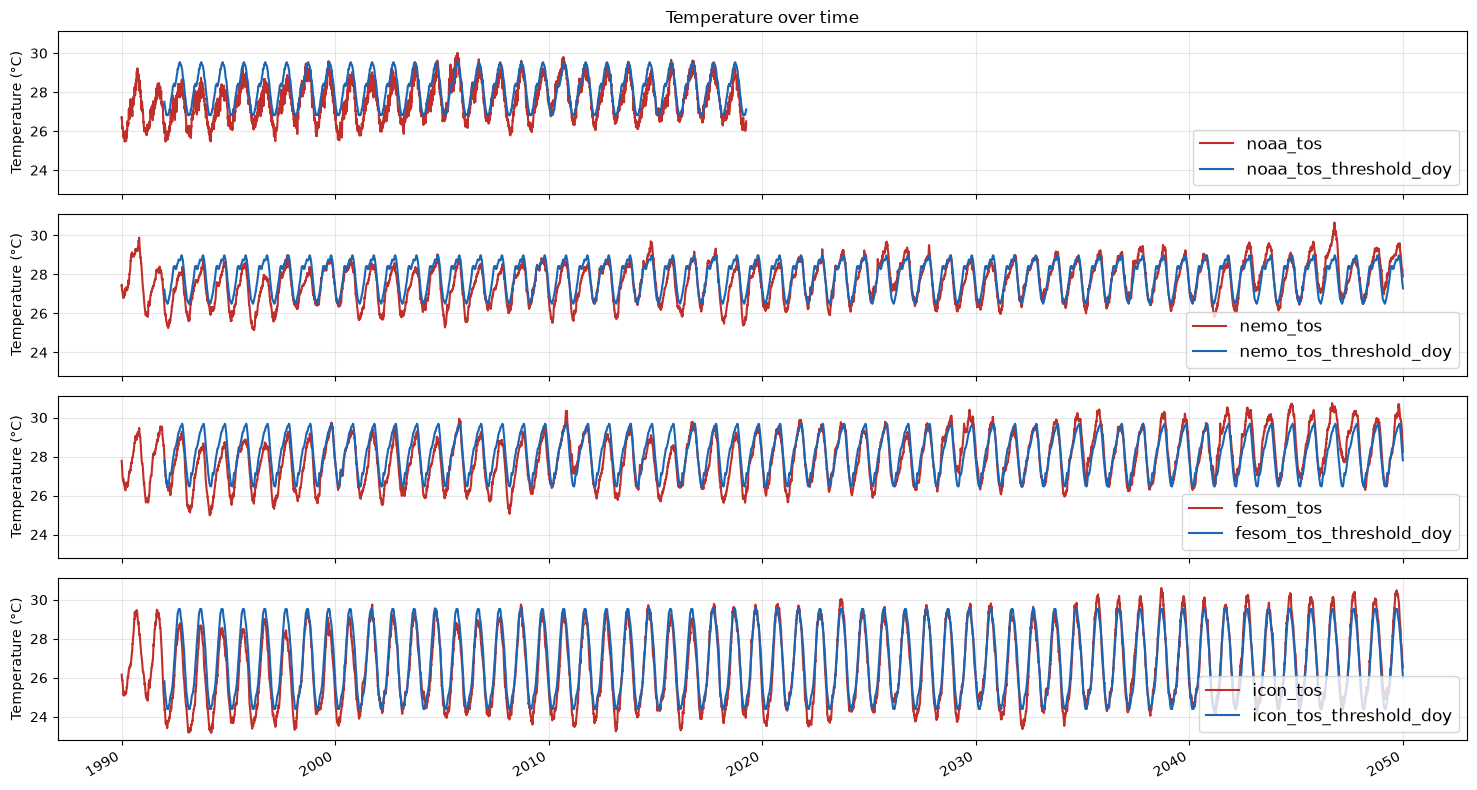

In [ ]:
# fs = 12

# # exps = ["noaa_tos", "noaa_tos_threshold_doy", "nemo_tos", "nemo_tos_threshold_doy"]
# exps = [
#     ["noaa_tos", "noaa_tos_threshold_doy"],
#     ["nemo_tos", "nemo_tos_threshold_doy"],
#     ["fesom_tos", "fesom_tos_threshold_doy"],
#     ["icon_tos", "icon_tos_threshold_doy"]

# ]
# colors = [ "#c02f2a", "#1a65b4", "#000000",  "#8d46c7"] # sns.dark_palette("xkcd:golden", 8)

# fig, axes = plt.subplots(len(exps), 1, figsize=(15, 8), sharex=True, sharey=True)

# for big_index, exp_group in enumerate(exps):

#     ax = axes[big_index]

#     for index, exp in enumerate(exp_group):

#         try:
#             to_plot = globals()[f"{exp}"].mean(dim = ["lat", "lon"])
#         except ValueError:
#             to_plot = globals()[f"{exp}"]

#         ax.plot(to_plot.time, to_plot,  
#                 color=colors[index],
#                 label = exp,
#                 linewidth=1.5)

#     ax.grid(alpha=0.3)
#     ax.set_ylabel("Temperature (°C)")
#     ax.legend(fontsize = fs, loc = "lower right")

#     if big_index == 0:
#         ax.set_xlabel("Time")
#         ax.set_title("Temperature over time")

# fig.autofmt_xdate()  # rotates date labels for readability

# plt.tight_layout()
# plt.show()

In [ ]:

# exps = ["noaa_tos","nemo_tos", "fesom_tos", "icon_tos"]

# # detect MHW over the whole period 
# for exp in exps:
#     ds = globals()[f"{exp}"]
#     ds = ds.mean(dim=["lat", "lon"], skipna=True)
#     globals()[f"{exp}_mhw_ds"] = detect_mhw_events(
#                                     ds.sel(time = slice(start_time, None)), 
#                                     globals()[f"{exp}_threshold_doy"], 
#                                     min_duration=5
#                                 )

#     globals()[f"{exp}_mhw_summary"]  = summarize_mhw_events(
#                                     globals()[f"{exp}_mhw_ds"]
#                                 )

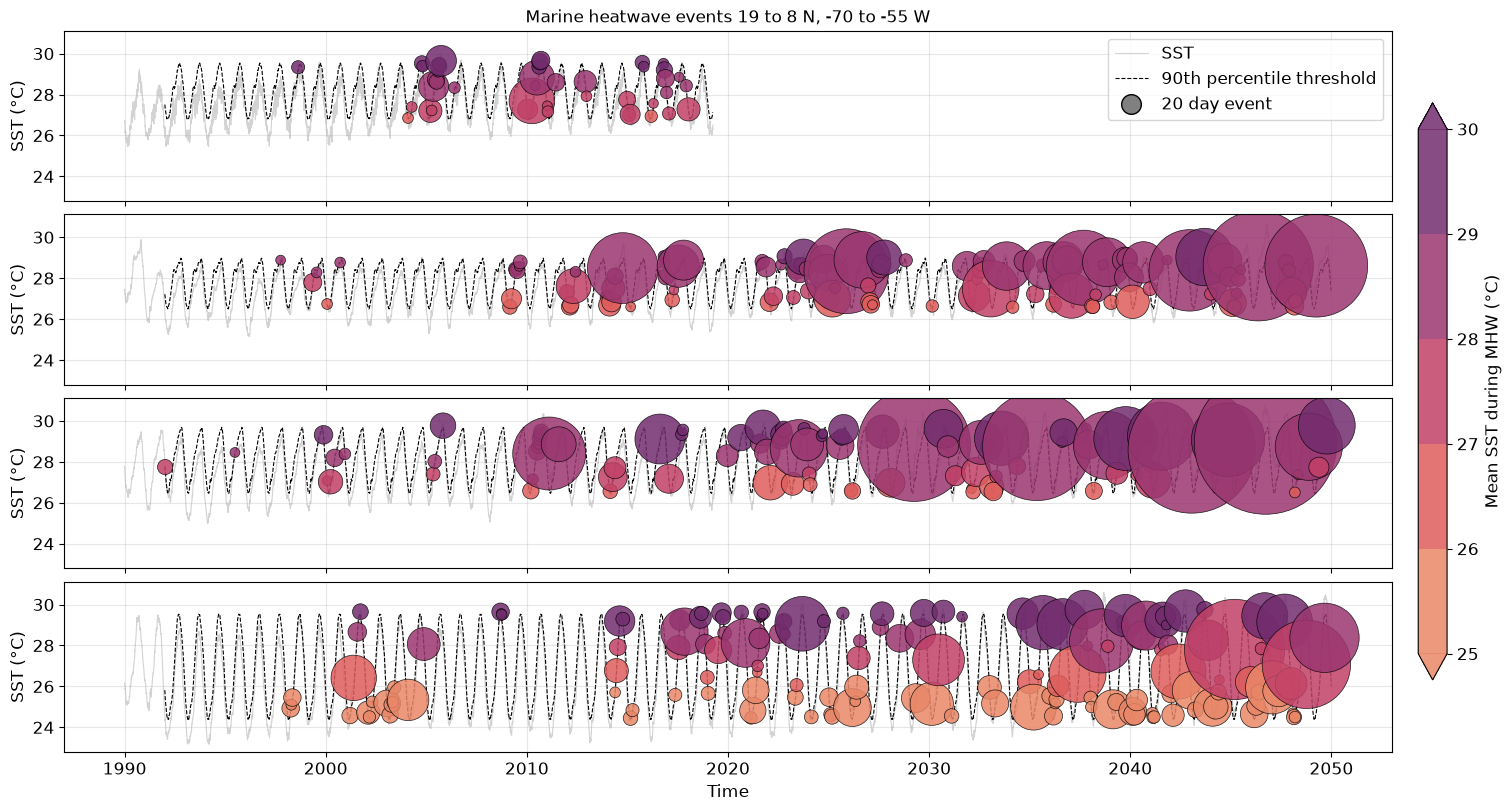

In [ ]:
# # --- Plot ---
# fs = 12 

# exps = [
#     ["noaa_tos", "noaa_tos_threshold_doy"],
#     ["nemo_tos", "nemo_tos_threshold_doy"],
#     ["fesom_tos", "fesom_tos_threshold_doy"],
#     ["icon_tos", "icon_tos_threshold_doy"]
# ]

# fig, axes = plt.subplots(len(exps), 1, figsize=(15, 8), 
#                          sharex=True, 
#                          sharey=True, 
#                          constrained_layout = True
#                         )

# for big_index, exp_group in enumerate(exps):

#     ax = axes[big_index]

#     to_plot = globals()[f"{exp_group[0]}"].mean(dim = ["lat", "lon"])
#     to_plot_threshold = globals()[f"{exp_group[1]}"] # .mean(dim = ["lat", "lon"])

#     # Optional: plot the full SST time series in the background for context
#     ax.plot(to_plot.time, to_plot, color="lightgray", linewidth=0.8, zorder=1, label="SST")
#     ax.plot(to_plot_threshold.time, to_plot_threshold, color="black",
#             linewidth=0.8, linestyle="--", zorder=1, label=f"{percentile}th percentile threshold")

#     palette = sns.color_palette("flare", 5)
#     cmap = ListedColormap(palette)

#     # --- Summarize events ---
#     event_summary = globals()[f"{exp_group[0]}_mhw_summary"] 

#     # Bubble scatter: size ~ duration, color ~ mean temperature
#     scale_factor = 10  # adjust so bubble sizes look reasonable 
#     sc = ax.scatter(
#         event_summary["mid_time"],
#         event_summary["mean_sst"],
#         s=event_summary["duration"] * scale_factor,
#         c=event_summary["mean_sst"],
#         vmin=25, vmax=30,
#         cmap=cmap,
#         edgecolor="black",
#         linewidth=0.5,
#         alpha=0.85,
#         zorder=2
#     )

#     example_duration = 20
#     example_size = example_duration * scale_factor  # matches the 's=' scaling used in scatter

#     size_legend_marker = Line2D(
#         [], [],
#         marker='o',
#         color='w',
#         markerfacecolor='gray',
#         markeredgecolor='black',
#         markersize=np.sqrt(example_size),  # scatter uses area (s=), legend markersize is linear
#         linestyle='None',
#         label=f'{example_duration} day event'
#     )

#     ax.grid(alpha=0.3)

#     if big_index == 0:
#         ax.set_title(
#             f"Marine heatwave events {lat_bounds[0]} to {lat_bounds[1]} N, {lon_bounds[0]} to {lon_bounds[1]} W",
#             fontsize = fs)
#         #ax.legend(loc="upper left", fontsize = fs)
#     elif big_index == len(exps)-1:
#         ax.set_xlabel("Time", fontsize = fs)

#     ax.set_ylabel("SST (°C)", fontsize = fs)
#     ax.tick_params(labelsize = fs)

# cbar = fig.colorbar(sc, ax=axes, orientation = "vertical", 
#                 shrink = 0.8, 
#                 location = "right",
#                 pad = 0.02,
#                 extend = "both"
#             )

# cbar.set_label("Mean SST during MHW (°C)", fontsize = fs)
# cbar.ax.tick_params(labelsize=fs)

# # Combine with your existing line legend (SST / threshold), or make a separate one
# existing_handles, existing_labels = axes[0].get_legend_handles_labels()
# axes[0].legend(
#     handles=existing_handles + [size_legend_marker],
#     loc='upper right', fontsize = fs
# )

# #plt.tight_layout()
# plt.show()

In [ ]:
# # --- Compute stats for both periods ---

# exps = ["noaa_tos", "nemo_tos", "fesom_tos", "icon_tos"]
# for exp in exps:

#     print(exp)
#     event_summary = globals()[f"{exp}_mhw_summary"]

#     stats_1990_2019 = summarize_period(event_summary, 
#                                        int(start_time[:4]), 
#                                        int(end_time[:4])
#                                     )

#     if exp in ["nemo_tos", "fesom_tos", "icon_tos"]:
#         stats_2020_2050 = summarize_period(event_summary,
#                                         2020, 
#                                         2050
#                                     )

#         # --- Print comparison ---
#         print("=" * 60)
#         print(f"MHW SUMMARY: {int(start_time[:4])}-{int(end_time[:4])} vs 2020-2050 for {exp}")
#         print("=" * 60)

#         print(f"\n{'Metric':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}{'2020-2050':>15}")
#         print("-" * 60)
#         print(f"{'Number of events':<30}{stats_1990_2019['n_events']:>15}{stats_2020_2050['n_events']:>15}")
#         print(f"{'Total MHW days':<30}{stats_1990_2019['total_mhw_days']:>15.0f}{stats_2020_2050['total_mhw_days']:>15.0f}")
#         print(f"{'% of days as MHW':<30}{stats_1990_2019['pct_days_mhw']:>14.2f}%{stats_2020_2050['pct_days_mhw']:>14.2f}%")
#         print(f"{'Overall mean event temp (°C)':<30}{stats_1990_2019['overall_mean_temp']:>15.2f}{stats_2020_2050['overall_mean_temp']:>15.2f}")
#         print(f"{'Mean event duration (days)':<30}{stats_1990_2019['mean_duration']:>15.2f}{stats_2020_2050['mean_duration']:>15.2f}")

#         print(f"\n{'Seasonal mean event temp (°C)':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}{'2020-2050':>15}{'Change':>12}")
#         print("-" * 72)
#         for season in ["DJF", "MAM", "JJA", "SON"]:
#             t1 = stats_1990_2019["seasonal_mean_temp"].get(season, np.nan)
#             t2 = stats_2020_2050["seasonal_mean_temp"].get(season, np.nan)
#             change = t2 - t1
#             print(f"{season:<30}{t1:>15.2f}{t2:>15.2f}{change:>+12.2f}")

#         print(f"\n{'Seasonal event count':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}{'2020-2050':>15}{'Change':>12}")
#         print("-" * 72)
#         for season in ["DJF", "MAM", "JJA", "SON"]:
#             c1 = stats_1990_2019["seasonal_event_count"].get(season, 0)
#             c2 = stats_2020_2050["seasonal_event_count"].get(season, 0)
#             print(f"{season:<30}{c1:>15}{c2:>15}{c2 - c1:>+12}")

#         print("\n" + "=" * 60)
#         print(f"OVERALL CHANGES (2020-2050 minus {int(start_time[:4])}-{int(end_time[:4])})")
#         print("=" * 60)
#         print(f"Δ Number of events:         {stats_2020_2050['n_events'] - stats_1990_2019['n_events']:+d}")
#         print(f"Δ Total MHW days:           {stats_2020_2050['total_mhw_days'] - stats_1990_2019['total_mhw_days']:+.0f}")
#         print(f"Δ % of days as MHW:         {stats_2020_2050['pct_days_mhw'] - stats_1990_2019['pct_days_mhw']:+.2f} pp")
#         print(f"Δ Overall mean event temp:  {stats_2020_2050['overall_mean_temp'] - stats_1990_2019['overall_mean_temp']:+.2f} °C")
#         print(f"Δ Mean event duration:      {stats_2020_2050['mean_duration'] - stats_1990_2019['mean_duration']:+.2f} days")

#     else:
#         # --- Print statistics for 1990-2019 only ---
#         print("=" * 60)
#         print(f"MHW SUMMARY: {int(start_time[:4])}-{int(end_time[:4])} for {exp}")
#         print("=" * 60)

#         print(f"{'Metric':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}")
#         print("-" * 45)

#         print(f"{'Number of events':<30}{stats_1990_2019['n_events']:>15}")
#         print(f"{'Total MHW days':<30}{stats_1990_2019['total_mhw_days']:>15.0f}")
#         print(f"{'% of days as MHW':<30}{stats_1990_2019['pct_days_mhw']:>14.2f}%")
#         print(f"{'Overall mean event temp (°C)':<30}{stats_1990_2019['overall_mean_temp']:>15.2f}")
#         print(f"{'Mean event duration (days)':<30}{stats_1990_2019['mean_duration']:>15.2f}")

#         print(f"\n{'Seasonal mean event temp (°C)':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}")
#         print("-" * 45)

#         for season in ["DJF", "MAM", "JJA", "SON"]:
#             t = stats_1990_2019["seasonal_mean_temp"].get(season, np.nan)
#             print(f"{season:<30}{t:>15.2f}")

#         print(f"\n{'Seasonal event count':<30}{f'{int(start_time[:4])}-{int(end_time[:4])}':>15}")
#         print("-" * 45)

#         for season in ["DJF", "MAM", "JJA", "SON"]:
#             c = stats_1990_2019["seasonal_event_count"].get(season, 0)
#             print(f"{season:<30}{c:>15}")

#         print("\n" + "=" * 60)

noaa_tos
MHW SUMMARY: 1992-2018 for noaa_tos
Metric                              1992-2018
---------------------------------------------
Number of events                           42
Total MHW days                            703
% of days as MHW                        7.13%
Overall mean event temp (°C)            28.37
Mean event duration (days)              16.74

Seasonal mean event temp (°C)       1992-2018
---------------------------------------------
DJF                                     27.44
MAM                                     27.69
JJA                                     29.08
SON                                     29.33

Seasonal event count                1992-2018
---------------------------------------------
DJF                                        12
MAM                                         9
JJA                                        11
SON                                        10

nemo_tos
MHW SUMMARY: 1992-2018 vs 2020-2050 for nemo_tos

Metric             

# seeing how the statistics compare against observed SST over the last 30 years

In [ ]:
exps = ["noaa_tos"]

clim_start = "1990-01-01"
clim_end = "2019-12-31"

percentile = 90

for exp in exps:
    da = globals()[f'{exp}']


    # Subset to the climatology baseline period
    da_clim = da.sel(time=slice(clim_start, clim_end))

    # Collapse to domain-averaged SST (1D time series)
    # adjust dim names ('lat','lon') to match your dataset
    da_mean_clim = da_clim.mean(dim=["lat", "lon"], skipna=True)

    # Compute day-of-year 90th percentile threshold with 11-day window
    threshold_doy = percentile_doy(
        da_mean_clim,
        window=11,
        per=percentile
    )

    if "percentiles" in threshold_doy.coords:
        threshold_doy = threshold_doy.squeeze("percentiles", drop=True)

    # ignoring the first 2 years 
    to_plot = noaa_tos.sel(time = slice(clim_start, clim_end))
    threshold_full = threshold_doy.sel(dayofyear=to_plot.time.dt.dayofyear)
    globals()[f"{exp}_threshold_doy"] = threshold_full



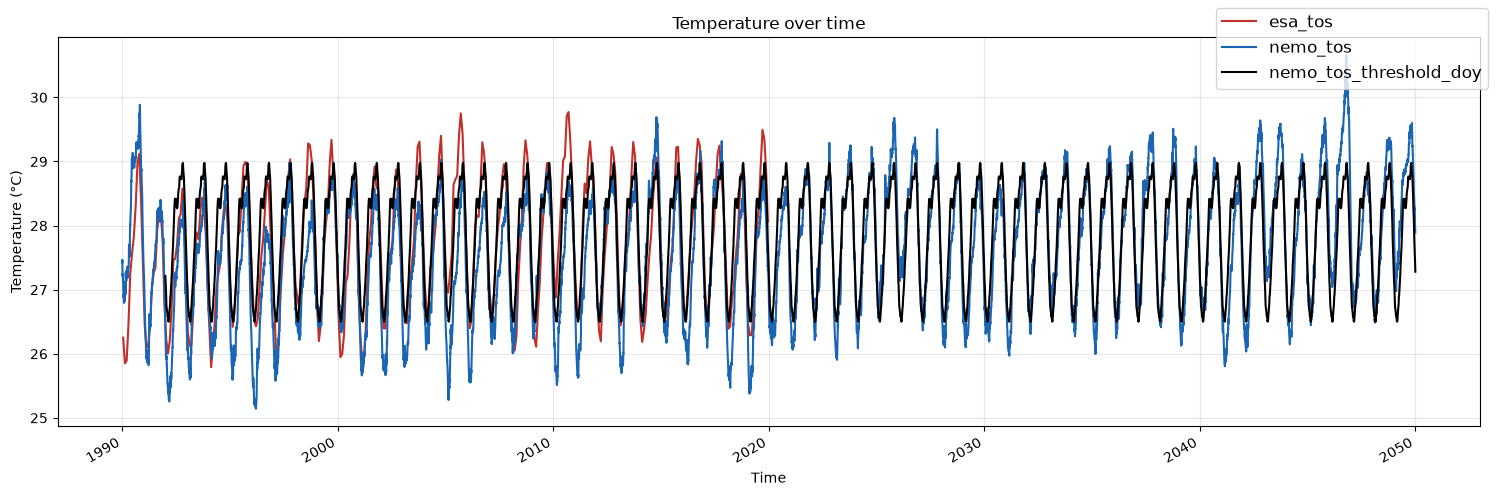

In [ ]:
# plot no longer so comparable because plotting daily data 

fs = 12

exps = ["esa_tos", "nemo_tos", "nemo_tos_threshold_doy"]

colors = [ "#c02f2a", "#1a65b4", "#000000",  "#8d46c7"] # sns.dark_palette("xkcd:golden", 8)

fig, ax = plt.subplots(figsize=(15, 5))

for index, exp in enumerate(exps):
    try:
        to_plot = globals()[f"{exp}"].mean(dim = ["lat", "lon"])
    except ValueError:
        to_plot = globals()[f"{exp}"]

    ax.plot(to_plot.time, to_plot,  
            color=colors[index],
            label = exp,
            linewidth=1.5)

ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature over time")

fig.legend(fontsize = fs)

ax.grid(alpha=0.3)
fig.autofmt_xdate()  # rotates date labels for readability

plt.tight_layout()
plt.show()

# Fourier decomposition of main frequencies in signal

/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/b/b382291/.con

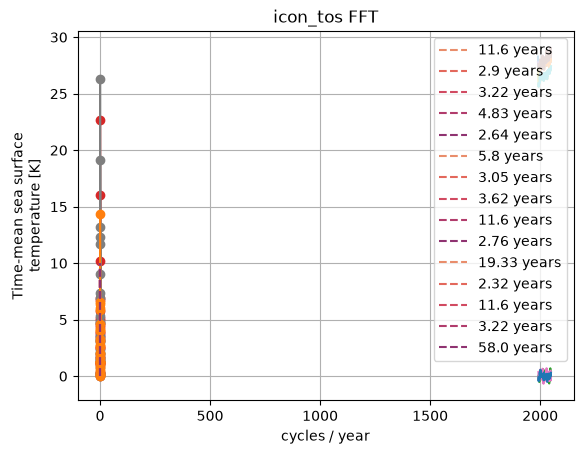

In [ ]:
real_start = "1990-01-01"
clim_start = "1992-01-01"
clim_end = "2050-12-31"

exps = ["nemo_tos", "fesom_tos", "icon_tos"]

for exp in exps:
    to_plot = globals()[f"{exp}"]
    settled_ocean_temp = to_plot.sel(time=slice(clim_start, clim_end)).mean(dim = ["lat", "lon"])
    ocean_temp = to_plot.sel(time=slice(real_start, clim_end)).mean(dim = ["lat", "lon"])


    settled_ocean_temp = settled_ocean_temp.groupby('time.year').mean()
    ocean_temp = ocean_temp.groupby('time.year').mean()

    ocean_temp.plot()

    settled_ocean_temp.plot()

    fit=sstats.linregress(settled_ocean_temp.year,settled_ocean_temp)
    best_fit=fit.slope*settled_ocean_temp.year + fit.intercept
    detrended_temp=settled_ocean_temp-best_fit
    detrended_temp.plot() 


    color = sns.color_palette("flare", 6)


    spec=np.fft.rfft(detrended_temp)
    power=spec*np.conj(spec)
    freq=np.fft.rfftfreq(len(detrended_temp))
    plt.plot(freq, power, marker='o')
    plt.grid()
    plt.xlabel("cycles / year")
    for i in range(5): 
        loc = np.where(power == np.flip(np.sort(power))[i])
        plt.vlines(freq[loc], 0,10,linestyles='--',colors=color[i],label= f'{np.round(1/freq[loc][0],2)} years') 

    plt.legend(loc = "upper right")
    plt.title(f"{exp} FFT")

# doing the same for obs 

/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/b/b382291/.conda/envs/aqua_26/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


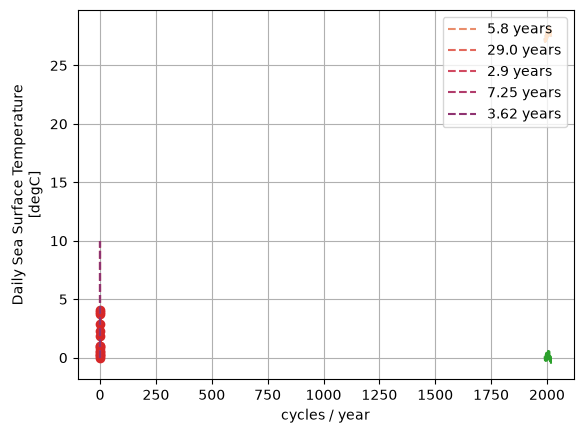

In [ ]:
real_start = "1990-01-01"
clim_start = "1990-01-01"
clim_end = "2018-12-31"

settled_ocean_temp = noaa_tos.sel(time=slice(clim_start, clim_end)).mean(dim = ["lat", "lon"])
ocean_temp = noaa_tos.sel(time=slice(real_start, clim_end)).mean(dim = ["lat", "lon"])


settled_ocean_temp = settled_ocean_temp.groupby('time.year').mean()
ocean_temp = ocean_temp.groupby('time.year').mean()

ocean_temp.plot()

settled_ocean_temp.plot()

fit=sstats.linregress(settled_ocean_temp.year,settled_ocean_temp)
best_fit=fit.slope*settled_ocean_temp.year + fit.intercept
detrended_temp=settled_ocean_temp-best_fit
detrended_temp.plot() 

color = sns.color_palette("flare", 6)


spec=np.fft.rfft(detrended_temp)
power=spec*np.conj(spec)
freq=np.fft.rfftfreq(len(detrended_temp))
plt.plot(freq, power, marker='o')
plt.grid()
plt.xlabel("cycles / year")
for i in range(5): 
    loc = np.where(power == np.flip(np.sort(power))[i])
    plt.vlines(freq[loc], 0,10,linestyles='--',colors=color[i],label= f'{np.round(1/freq[loc][0],2)} years') 

plt.legend(loc = "upper right")

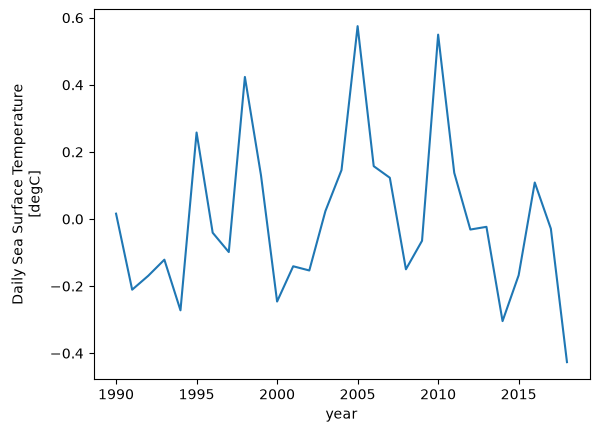

In [ ]:
fit=sstats.linregress(settled_ocean_temp.year,settled_ocean_temp)
best_fit=fit.slope*settled_ocean_temp.year + fit.intercept
detrended_temp=settled_ocean_temp-best_fit
detrended_temp.plot() 

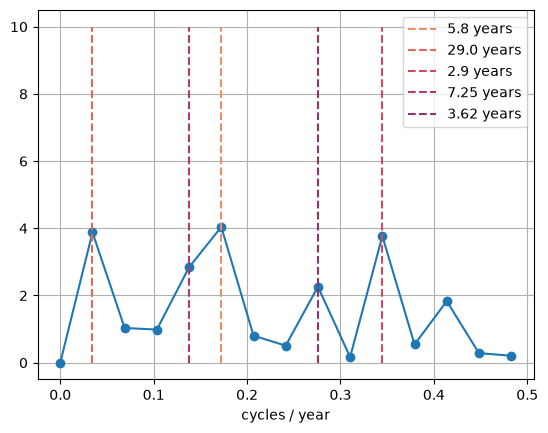

In [ ]:
color = sns.color_palette("flare", 6)


spec=np.fft.rfft(detrended_temp)
power=spec*np.conj(spec)
freq=np.fft.rfftfreq(len(detrended_temp))
plt.plot(freq, power, marker='o')
plt.grid()
plt.xlabel("cycles / year")
for i in range(5): 
    loc = np.where(power == np.flip(np.sort(power))[i])
    plt.vlines(freq[loc], 0,10,linestyles='--',colors=color[i],label= f'{np.round(1/freq[loc][0],2)} years') 

plt.legend(loc = "upper right")